# mpstab, qibojit and PauliPropagation.jl: who wins where

No simulator is best at everything. This notebook runs the same circuits through three very different simulators and shows, with errors and wall-clock times, in which regime each one wins:

- **mpstab**: the HSMPO surrogate, a stabilizer tableau for the Clifford gates and an MPS for the magic ones;
- **qibojit** (qibo's numba backend): an exact statevector, or an exact density matrix when there is noise;
- **PauliPropagation.jl**: the observable propagated backwards through the circuit as a sum of Pauli strings, dropping terms with coefficients below `min_abs_coeff`.

In short:

| regime | best choice | why |
|---|---|---|
| few qubits (≲ 24), any circuit | qibojit as the reference | exact, with nothing to tune; its cost doubles with every qubit, and noise (a density matrix) squares it |
| shallow circuits, local observable | Pauli propagation | the observable's light cone holds a handful of Pauli strings |
| noisy circuits, local observable | Pauli propagation | noise damps Pauli strings, so truncation gets easier; mpstab samples faults and pays in time and variance |
| deep circuits, many qubits | **mpstab** | Pauli propagation's term count explodes with depth; the MPS bond dimension grows far more slowly |
| observables with many terms | **mpstab** | one MPS serves every term; Pauli propagation pays per term |
| many observables, same circuit | **mpstab** | the surrogate is built once; Pauli propagation propagates again for each |

## Setup

The helpers in `frameworks.py`, next to this notebook, wrap the three simulators behind the same interface. Running the notebook needs `qibojit`, `pandas` and `juliacall`; the first run downloads Julia and PauliPropagation.jl, which takes a few minutes.

**How we time.** Times are wall clock for one evaluation. For mpstab: everything, from splitting the circuit into Clifford and magic parts to the final MPS contraction. For qibojit: circuit execution and contraction, multithreaded, after a warm-up that compiles numba's kernels. For PauliPropagation.jl: the propagation alone, after Julia has compiled it. Runs that might blow up go to a separate Julia process that is stopped after `TIMEOUT` seconds.

**What "exact" means.** Errors are measured against qibojit where it fits in memory. Beyond that, the reference is mpstab with no bond-dimension cap and no SVD cutoff, which makes no approximation at all; we check it against qibojit in section 1.

In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import frameworks as fw
from mpstab import HSMPO
from mpstab.engines import QuimbEngine, StimEngine
sys.path.append("../..")  # examples/, home of the plot style
from plotting import COLORS, set_style

set_style()
pd.set_option("display.precision", 4)

TIMEOUT = 60  # seconds per isolated Pauli propagation run

qibojit = fw.qibojit_backend()  # compiles numba's kernels
pp = fw.PauliPropagation()      # installs and compiles PauliPropagation.jl

## 1. Sanity check: all three agree

A small kicked Ising circuit (8 qubits, 3 Floquet steps) and the observable $Z_0 Z_7$, first without noise and then with depolarizing noise after every gate plus $ZZ$ crosstalk. mpstab evaluates noise by summing the configurations with zero or one fault exactly and sampling those with more, so its noisy value carries a small statistical error, `stderr`.

In [2]:
n = 8
circuit = fw.kicked_ising(n, 3)
for name, events in [("noiseless", []), ("noisy", fw.noise_events(circuit, p=0.005, crosstalk=0.02))]:
    rows = fw.compare(circuit, events, fw.local_z(n), qibojit=qibojit, pauli_propagation=pp,
                      pp_options=dict(min_abs_coeff=1e-10),
                      mpstab_options=dict(n_samples=1000, seed=0))
    table = pd.DataFrame(rows).set_index("method")
    print(name)
    display(table[[c for c in ("value", "error", "stderr", "time") if c in table]])

noiseless


,value,error,time
method,,,
mpstab,0.3266,3.3307e-16,0.0036
qibojit,0.3266,NaN,0.0078
PauliPropagation,0.3266,8.8818e-16,0.0004


noisy


,value,error,stderr,time
method,,,,
mpstab,0.2405,4.4394e-04,0.0003,0.4430
qibojit,0.2401,NaN,NaN,0.1722
PauliPropagation,0.2401,4.9314e-12,NaN,0.0010


Without noise the three values agree to $10^{-15}$. With noise, Pauli propagation still matches qibojit to $10^{-11}$, and mpstab lands within about one and a half `stderr` of it. Even at 8 qubits, Pauli propagation is the fastest on this shallow circuit.

### The exact reference beyond qibojit

mpstab with no bond cap and no SVD cutoff, against the qibojit statevector, on 6 Floquet steps and $\langle Z_{n/2}\rangle$. From here on it serves as the exact value wherever qibojit does not fit.

In [3]:
for n in (12, 16, 20, 24):
    circuit, observable = fw.kicked_ising(n, 6), fw.local_z(n, (n // 2,))
    reference = fw.run_qibojit(qibojit, circuit, [], observable)
    ours = fw.run_mpstab_exact(circuit, observable)
    print(f"n={n}: |mpstab - qibojit| = {abs(ours['value'] - reference['value']):.1e}   "
          f"mpstab {ours['time']:.3f} s, qibojit {reference['time']:.3f} s")

n=12: |mpstab - qibojit| = 9.1e-15   mpstab 0.009 s, qibojit 0.023 s
n=16: |mpstab - qibojit| = 1.4e-14   mpstab 0.011 s, qibojit 0.038 s


n=20: |mpstab - qibojit| = 1.4e-14   mpstab 0.014 s, qibojit 0.147 s


n=24: |mpstab - qibojit| = 1.7e-14   mpstab 0.016 s, qibojit 3.133 s


The two agree to $2\times10^{-14}$ at every size. mpstab stays around 0.02 s, while the statevector needs about 3 s at 24 qubits.

## 2. Where Pauli propagation wins

### Shallow circuits, local observables

A kicked Ising circuit with 3 Floquet steps and the two-site observable $Z_0 Z_{n-1}$. Its backward light cone holds only a few Pauli strings, whatever the width, so Pauli propagation has almost nothing to do. qibojit's time doubles with every qubit.

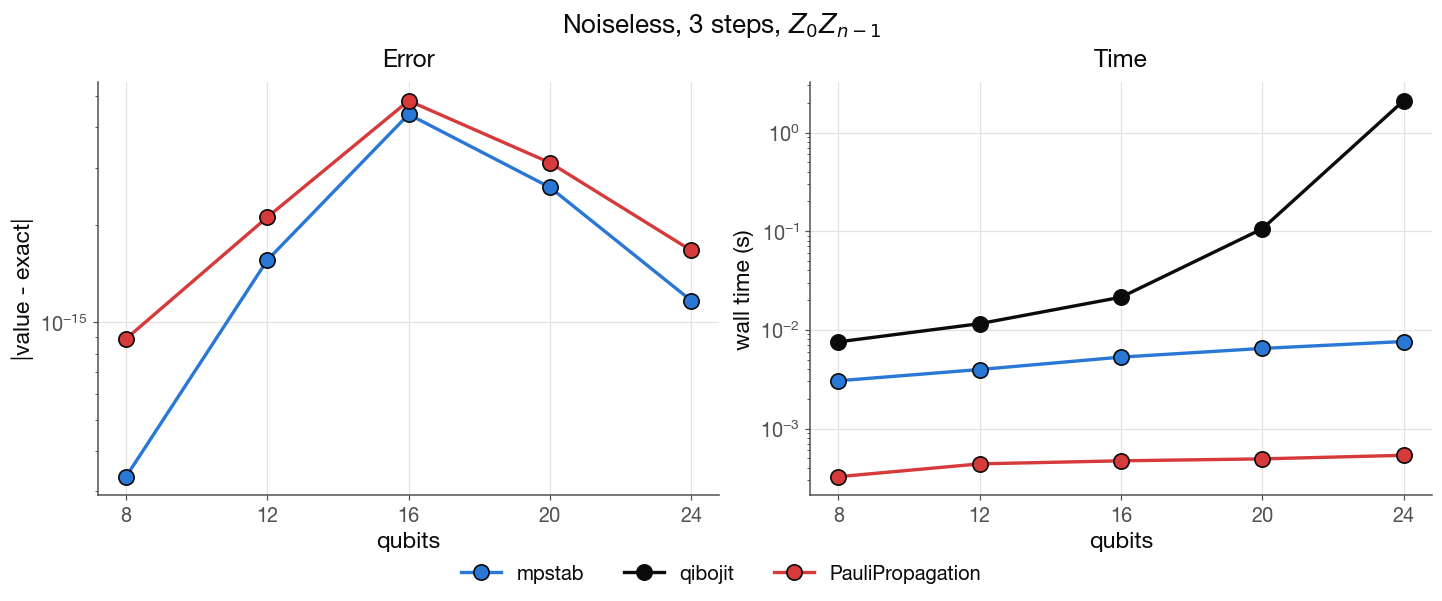

In [4]:
SIZES = [8, 12, 16, 20, 24]
shallow = fw.sweep(((n, fw.kicked_ising(n, 3), [], fw.local_z(n)) for n in SIZES), label="n",
                   qibojit=qibojit, pauli_propagation=pp, pp_options=dict(min_abs_coeff=1e-6))
fw.plot_methods(shallow, "n", "qubits", title=r"Noiseless, 3 steps, $Z_0 Z_{n-1}$")

All three agree to machine precision. Pauli propagation takes well under a millisecond at every width, about ten times less than mpstab; qibojit is the slowest, and grows from 10 ms at 8 qubits to about 2 s at 24.

### With noise

The same observable with 2 Floquet steps, depolarizing noise after every gate ($p = 0.005$) and $ZZ$ crosstalk. Noise helps Pauli propagation: it simply damps every Pauli string, at no extra cost and with no variance. mpstab samples the configurations with two or more faults, which costs time and leaves a statistical error (dotted line). qibojit's density matrix stops at 13 qubits.

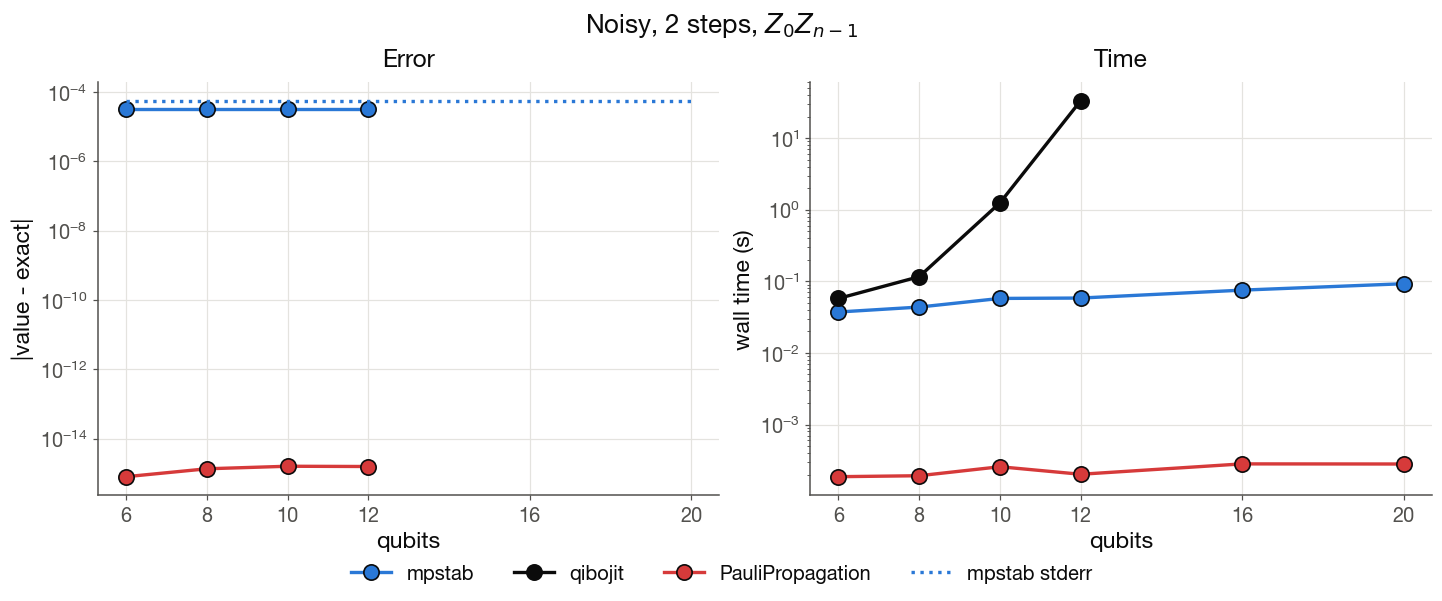

In [5]:
def noisy_case(n, steps):
    circuit = fw.kicked_ising(n, steps)
    return circuit, fw.noise_events(circuit, p=0.005, crosstalk=0.02), fw.local_z(n)


SIZES = [6, 8, 10, 12, 16, 20]
noisy = fw.sweep(((n, *noisy_case(n, 2)) for n in SIZES), label="n", qibojit=qibojit,
                 pauli_propagation=pp, pp_options=dict(min_abs_coeff=1e-6),
                 mpstab_options=dict(n_samples=1000, seed=0))
fw.plot_methods(noisy, "n", "qubits", title=r"Noisy, 2 steps, $Z_0 Z_{n-1}$", stderr=True)

Pauli propagation matches the density matrix to $10^{-14}$ in under a millisecond. mpstab is within its statistical error, a few times $10^{-5}$, in about 0.1 s, and its cost barely grows with width. The density matrix takes about half a minute at 12 qubits.

## 3. Where mpstab wins

### Depth

48 qubits, $\langle Z_{24}\rangle$, and an increasing number of Floquet steps. The number of Pauli strings grows exponentially with the number of magic gates in the light cone, so Pauli propagation needs a small `min_abs_coeff` to stay accurate, and then its runtime explodes. mpstab's cost follows the MPS bond dimension, which grows much more slowly. We run mpstab exactly (the reference) and with a cap $\chi = 64$.

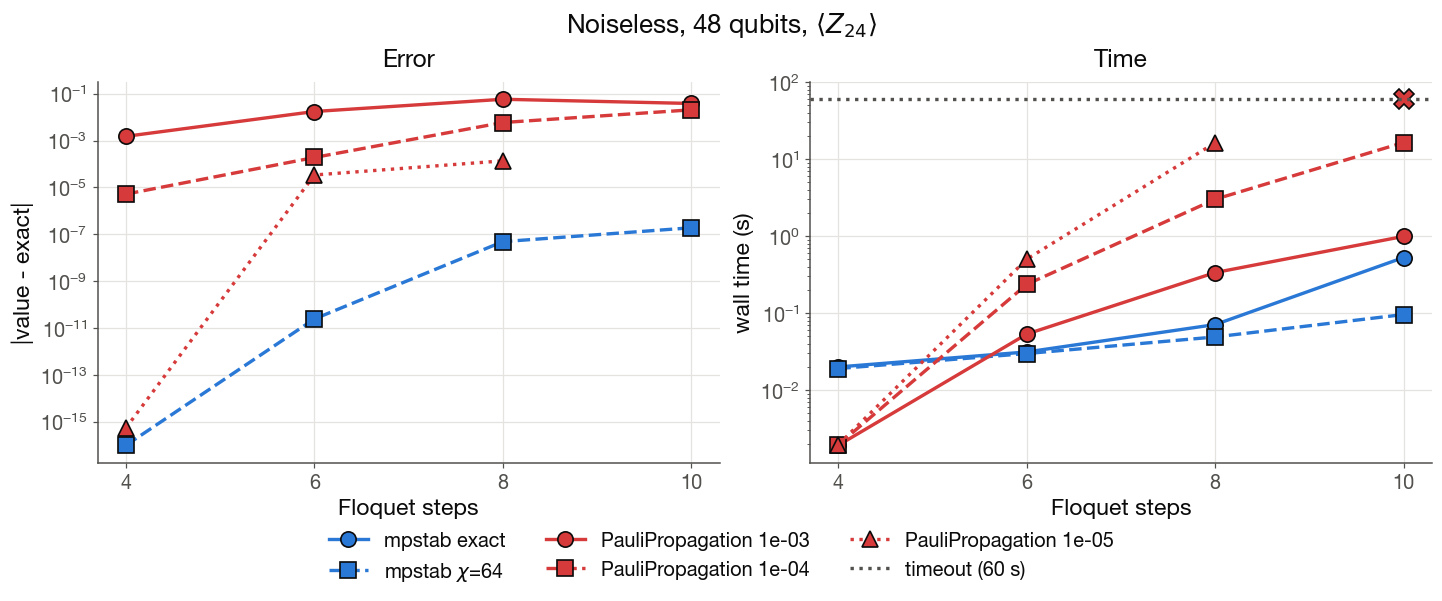

In [6]:
N, STEPS = 48, [4, 6, 8, 10]
observable = fw.local_z(N, (N // 2,))
isolated = fw.IsolatedPP(timeout=TIMEOUT)
rows = []
for steps in STEPS:
    circuit = fw.kicked_ising(N, steps)
    exact = fw.run_mpstab_exact(circuit, observable)
    rows.append(dict(method="mpstab exact", steps=steps, error=np.nan, time=exact["time"]))
    capped = fw.run_mpstab(circuit, observable, max_bond=64)
    rows.append(dict(method=r"mpstab $\chi$=64", steps=steps,
                     error=abs(capped["value"] - exact["value"]), time=capped["time"]))
    for threshold in (1e-3, 1e-4, 1e-5):
        row = isolated(circuit, observable, threshold, exact["value"],
                       warmup_gates=len(circuit.queue) // steps)
        rows.append(dict(row, steps=steps))
deep = pd.DataFrame(rows)
fw.plot_methods(deep, "steps", "Floquet steps", timeout=TIMEOUT,
                title=rf"Noiseless, {N} qubits, $\langle Z_{{{N // 2}}}\rangle$")

At 4 steps Pauli propagation is ten times faster than mpstab, and exact at the tightest threshold. From 6 steps on it can no longer be both fast and accurate: `1e-3` stays about as fast as exact mpstab but is off by $10^{-2}$ or more, `1e-4` takes 16 s at 10 steps for a $2\times10^{-2}$ error, and `1e-5` reaches $10^{-4}$ in 16 s at 8 steps and times out at 10. Exact mpstab needs 0.5 s at 10 steps, and the capped $\chi = 64$ run is within $2\times10^{-7}$ of it in 0.1 s.

### Width

6 Floquet steps and $\langle Z_{n/2}\rangle$, on a growing number of qubits. Pauli propagation runs at `min_abs_coeff=1e-5`, its most accurate setting that finishes in the depth sweep above.

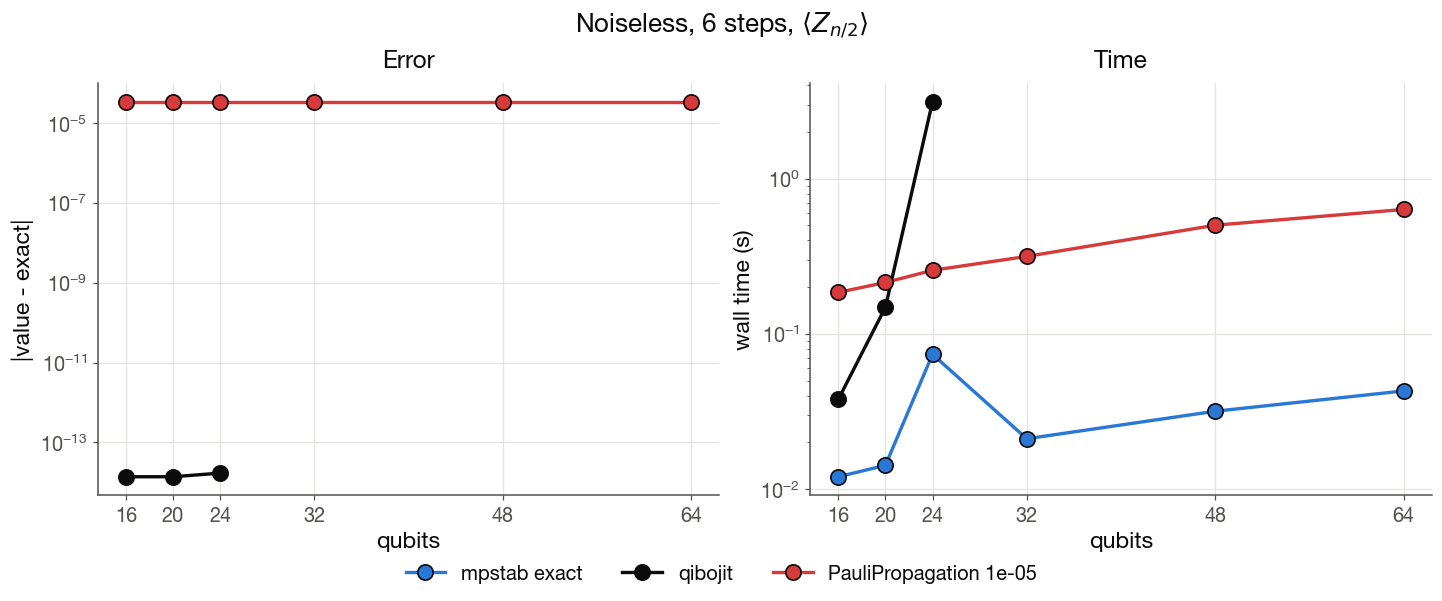

In [7]:
SIZES = [16, 20, 24, 32, 48, 64]
isolated = fw.IsolatedPP(timeout=TIMEOUT)
rows = []
for n in SIZES:
    circuit, observable = fw.kicked_ising(n, 6), fw.local_z(n, (n // 2,))
    exact = fw.run_mpstab_exact(circuit, observable)
    rows.append(dict(method="mpstab exact", n=n, error=np.nan, time=exact["time"]))
    if n <= 24:
        q = fw.run_qibojit(qibojit, circuit, [], observable)
        rows.append(dict(method="qibojit", n=n, error=abs(q["value"] - exact["value"]),
                         time=q["time"]))
    row = isolated(circuit, observable, 1e-5, exact["value"],
                   warmup_gates=len(circuit.queue) // 6)
    rows.append(dict(row, n=n))
wide = pd.DataFrame(rows)
fw.plot_methods(wide, "n", "qubits", timeout=TIMEOUT,
                title=r"Noiseless, 6 steps, $\langle Z_{n/2}\rangle$")

qibojit agrees with exact mpstab to $10^{-13}$, but its time grows to about 3 s at 24 qubits. Pauli propagation's error stays at about $3\times10^{-5}$ at every width and its time grows slowly, from 0.2 s to 0.6 s. Exact mpstab is faster still, under 0.1 s up to 64 qubits.

### Observables with many terms

The nearest-neighbour energy $\sum_i Z_i Z_{i+1}$ after 6 Floquet steps. mpstab contracts all $n-1$ terms against the same MPS, while in Pauli propagation the terms branch independently and the sum keeps growing.

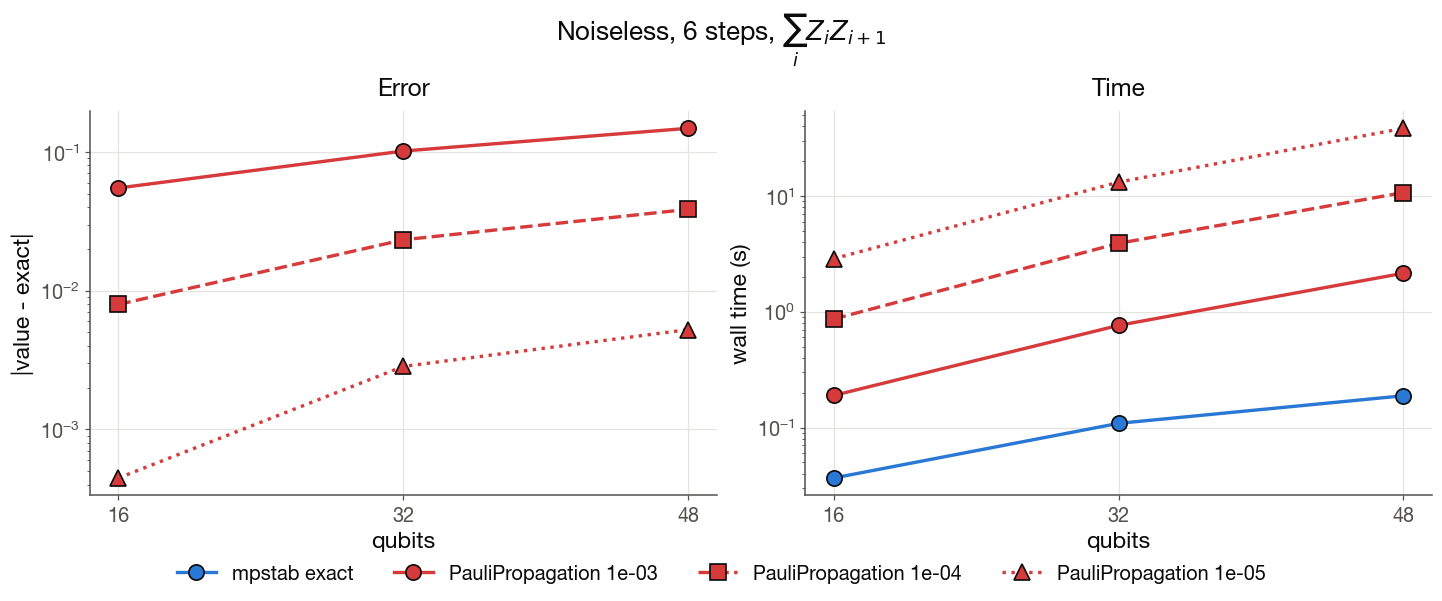

In [8]:
SIZES = [16, 32, 48]
isolated = fw.IsolatedPP(timeout=TIMEOUT)
rows = []
for n in SIZES:
    circuit, observable = fw.kicked_ising(n, 6), fw.zz_chain(n)
    exact = fw.run_mpstab_exact(circuit, observable)
    rows.append(dict(method="mpstab exact", n=n, error=np.nan, time=exact["time"]))
    for threshold in (1e-3, 1e-4, 1e-5):
        row = isolated(circuit, observable, threshold, exact["value"],
                       warmup_gates=len(circuit.queue) // 6)
        rows.append(dict(row, n=n))
terms = pd.DataFrame(rows)
fw.plot_methods(terms, "n", "qubits", timeout=TIMEOUT,
                title=r"Noiseless, 6 steps, $\sum_i Z_i Z_{i+1}$")

Every Pauli propagation setting is both slower and less accurate than exact mpstab. At 48 qubits, `1e-5` takes about 40 s and is still off by $5\times10^{-3}$; mpstab gives the exact value in 0.2 s.

## 4. Accuracy against cost

How much time does each method need to reach a given error? We take one case from each regime and turn each method's accuracy knob: the bond dimension $\chi$ (noiseless) or the number of samples `n_samples` (noisy) for mpstab, and `min_abs_coeff` for Pauli propagation. Each point is labelled with its knob value.

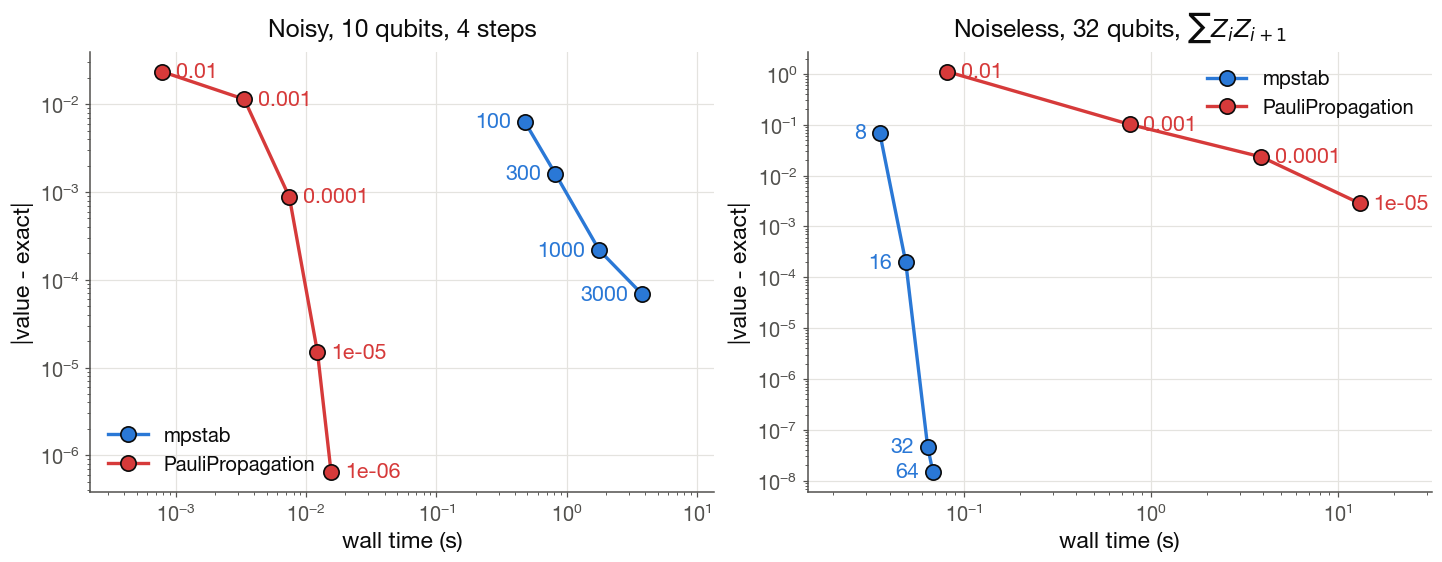

In [9]:
# Pauli propagation's regime: noisy, 10 qubits, 4 steps, Z_0 Z_9
circuit, events, observable = noisy_case(10, 4)
exact = fw.run_qibojit(qibojit, circuit, events, observable)["value"]
noisy_tradeoff = fw.tradeoff(circuit, events, observable, exact,
                             [100, 300, 1000, 3000], [1e-2, 1e-3, 1e-4, 1e-5, 1e-6], pp)

# mpstab's regime: noiseless, 32 qubits, 6 steps, sum Z_i Z_i+1
circuit, observable = fw.kicked_ising(32, 6), fw.zz_chain(32)
exact = fw.run_mpstab_exact(circuit, observable)["value"]
deep_tradeoff = fw.tradeoff(circuit, [], observable, exact, [8, 16, 32, 64],
                            [1e-2, 1e-3, 1e-4, 1e-5], pp)

fw.plot_tradeoff([("Noisy, 10 qubits, 4 steps", noisy_tradeoff),
                  (r"Noiseless, 32 qubits, $\sum Z_i Z_{i+1}$", deep_tradeoff)])

The two panels are mirror images. In the noisy case (left), Pauli propagation reaches $10^{-6}$ in under 20 ms, while mpstab needs 3000 samples and several seconds to get below $10^{-4}$: its error shrinks only as $1/\sqrt{n_\text{samples}}$. In the deep noiseless case (right), mpstab reaches $5\times10^{-8}$ at $\chi = 32$ in under 0.1 s, while Pauli propagation's best setting takes over 10 s for an error of $3\times10^{-3}$.

## 5. One build, many observables

So far every timing is for a single observable, and mpstab rebuilds its surrogate each time. For one observable that is the fair cost: building the surrogate *is* the computation, just as propagation is for Pauli propagation.

With many observables of the same circuit the two differ. mpstab evolves the MPS once, and each `expectation(O)` then only maps $O$ through the Clifford part and contracts it with the MPS. Pauli propagation works backwards from the observable, so every new observable is a new propagation through the whole circuit. We take 48 qubits, 6 Floquet steps, and 95 observables: every $Z_i$ and every $Z_i Z_{i+1}$. mpstab runs with no bond cap and no SVD cutoff, so its values are exact.

In [10]:
N, STEPS = 48, 6
circuit = fw.kicked_ising(N, STEPS)
observables = [fw.local_z(N, (i,)) for i in range(N)] + [fw.local_z(N, (i, i + 1)) for i in range(N - 1)]

# mpstab: build once, then one expectation per observable
start = time.perf_counter()
hsmpo = HSMPO.rotations_only(circuit)
hsmpo.progress = False
hsmpo.set_engines(stab_engine=StimEngine(), tn_engine=QuimbEngine(svd_cutoff=0.0))
build_time = time.perf_counter() - start
exact_values, mpstab_times = [], []
for observable in observables:
    start = time.perf_counter()
    exact_values.append(hsmpo.expectation(observable))
    mpstab_times.append(time.perf_counter() - start)
print(f"mpstab: build {build_time:.2f} s (largest bond {hsmpo.original_circuit_mps.max_bond()}), "
      f"then {np.mean(mpstab_times) * 1e3:.1f} ms per observable")

# Pauli propagation: one propagation per observable, Julia compiled first
pp.run(circuit, [], observables[N // 2], min_abs_coeff=1e-4, repeats=1)
pp_runs = {}
for threshold in (1e-4, 1e-5):
    pp_runs[threshold] = [pp.run(circuit, [], o, min_abs_coeff=threshold, repeats=1)
                          for o in observables]
    times = [r["time"] for r in pp_runs[threshold]]
    errors = [abs(r["value"] - v) for r, v in zip(pp_runs[threshold], exact_values)]
    print(f"PauliPropagation {threshold:.0e}: {np.mean(times) * 1e3:.0f} ms per observable, "
          f"largest error {max(errors):.1e}")

mpstab: build 0.19 s (largest bond 64), then 1.6 ms per observable


PauliPropagation 1e-04: 277 ms per observable, largest error 2.3e-03


PauliPropagation 1e-05: 719 ms per observable, largest error 3.6e-04


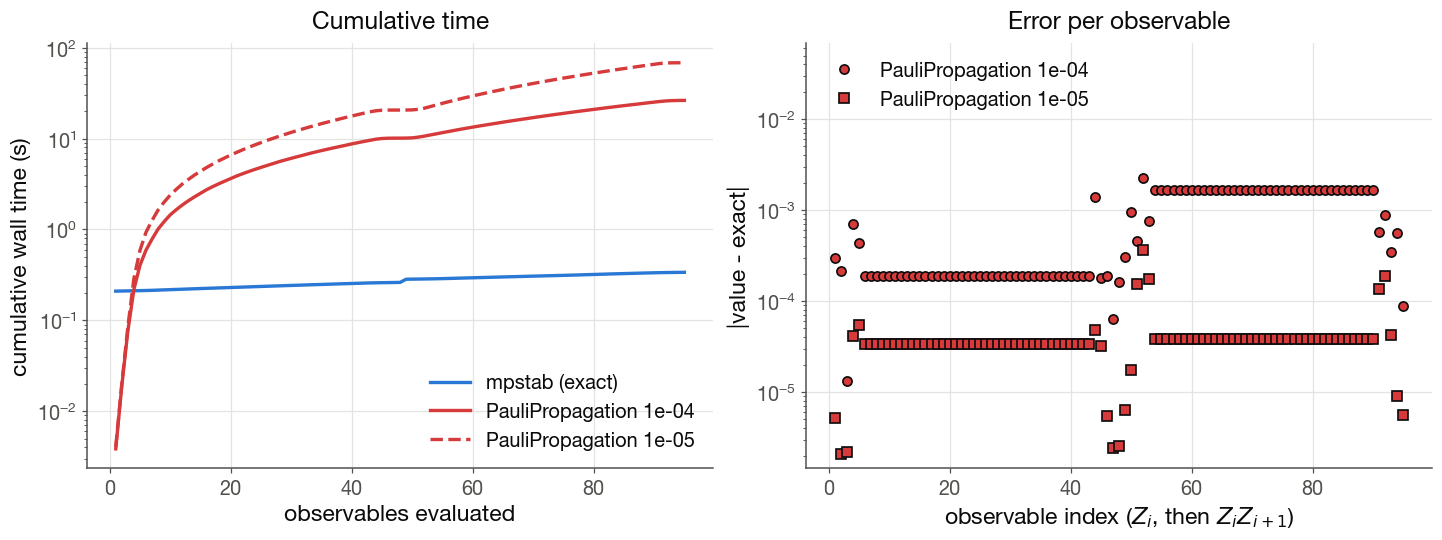

In [11]:
count = np.arange(1, len(observables) + 1)
fig, (ax_time, ax_error) = plt.subplots(1, 2, figsize=(13, 4.8))
ax_time.plot(count, build_time + np.cumsum(mpstab_times), color=COLORS["blue"],
             label="mpstab (exact)")
worst = 0.0
for (line, marker), (threshold, runs) in zip([("-", "o"), ("--", "s")], pp_runs.items()):
    label = f"PauliPropagation {threshold:.0e}"
    ax_time.plot(count, np.cumsum([r["time"] for r in runs]), line, color=COLORS["red"],
                 label=label)
    errors = [abs(r["value"] - v) for r, v in zip(runs, exact_values)]
    worst = max(worst, max(errors))
    ax_error.plot(count, np.clip(errors, fw.ERROR_FLOOR, None), marker, color=COLORS["red"],
                  markersize=6, label=label)
ax_time.set(yscale="log", xlabel="observables evaluated", ylabel="cumulative wall time (s)",
            title="Cumulative time")
ax_error.set(yscale="log", ylim=(None, 30 * worst),  # room for the legend
             xlabel=r"observable index ($Z_i$, then $Z_i Z_{i+1}$)",
             ylabel="|value - exact|", title="Error per observable")
ax_time.legend()
ax_error.legend(loc="upper left")
plt.show()

Building the surrogate takes 0.2 s, and each further observable a couple of milliseconds, so all 95 exact values cost about a third of a second. Pauli propagation pays 0.3 s per observable at `1e-4` (errors up to $2\times10^{-3}$) and 0.7 s at `1e-5` (errors up to $4\times10^{-4}$): about 26 s and 68 s in total.

## Playground

`fw.compare` runs every simulator that fits on any circuit, list of noise events and observable. Build events with `fw.noise_events`, or by hand with `PauliChannel` and `CoherentRotation` from `mpstab.models.noise.events`. Here: a 12-qubit hardware-efficient circuit with weak depolarizing noise and a two-term observable.

In [12]:
circuit = fw.hardware_efficient(12, 4, seed=1)
events = fw.noise_events(circuit, p=0.002)
observable = {"ZZ" + "I" * 10: 1.0, "I" * 5 + "XX" + "I" * 5: -0.5}
rows = fw.compare(circuit, events, observable, qibojit=qibojit, pauli_propagation=pp,
                  mpstab_options=dict(n_samples=1000, seed=0),
                  pp_options=dict(min_abs_coeff=1e-6))
pd.DataFrame(rows).set_index("method")[["value", "error", "stderr", "time"]]

,value,error,stderr,time
method,,,,
mpstab,0.4738,1.5444e-04,0.0002,2.7600
qibojit,0.4737,NaN,NaN,30.6473
PauliPropagation,0.4737,4.4409e-16,NaN,0.0003


## Takeaways

- **Pauli propagation** wins when the observable's backward light cone stays small: shallow circuits, local observables, and especially noisy circuits, where it is exact in under a millisecond.
- **mpstab** wins when depth or the number of terms makes the Pauli sum explode: at 48 qubits and 10 steps it is exact in half a second where Pauli propagation trades large errors against timeouts, and with many observables of one circuit it amortizes a single build.
- **qibojit** is the simplest exact reference up to about 24 qubits without noise and 12 with noise, but its cost grows exponentially.
- With noise, mpstab's sampled estimate converges as $1/\sqrt{n_\text{samples}}$; for noisy local observables, Pauli propagation is the better tool.